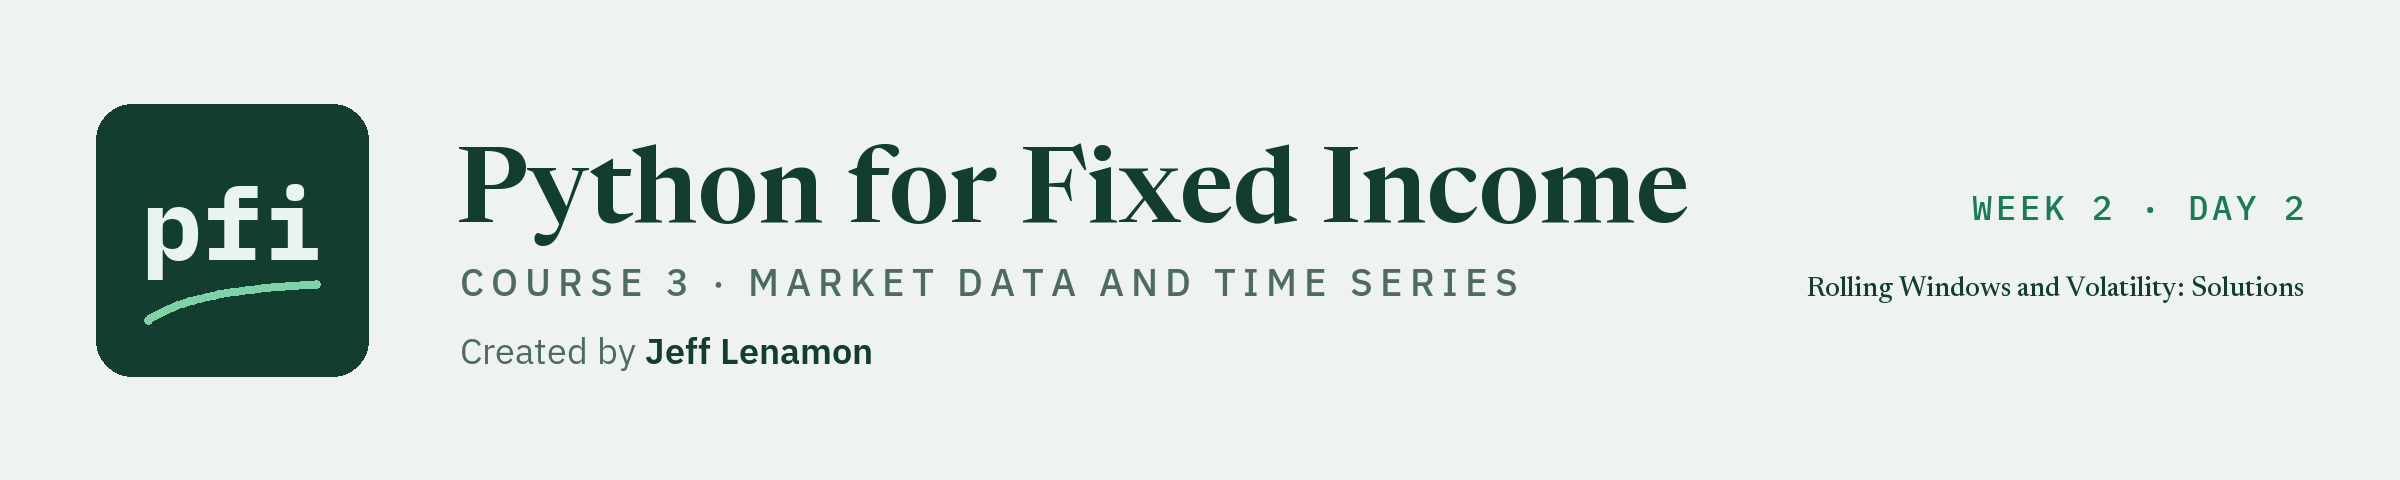

# Rolling Windows and Volatility: Solutions

Week 2, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day2/07_rolling_windows_and_volatility_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook leaves it, the data, the cut dates, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 07 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(7, after=7)

Work folder pfi_course3_07_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 07 left it, 7 commits, tagged week1


In [2]:
import importlib

import pandas as pd

import marketdata as md
from test_marketdata import CUT_DATES

treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
ten_changes = md.change_bp(treasury['10 Yr']).dropna()

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
# daily changes in bp: the 5 Yr is in percent, the spread already in bp
five_changes = md.change_bp(treasury['5 Yr']).dropna()
high_yield_changes = md.change_bp(spreads['hy_spread_bp'], percent_units=False).dropna()
ex1_five_year_bp = md.rolling_vol_bp(five_changes, window=21).loc['2026-10-02']
ex1_high_yield_bp = md.rolling_vol_bp(high_yield_changes, window=21).loc['2026-10-02']
print(f'5 Yr {ex1_five_year_bp:.2f} bp a day; high yield spread (synthetic) '
      f'{ex1_high_yield_bp:.2f} bp a day')

5 Yr 6.03 bp a day; high yield spread (synthetic) 5.43 bp a day


In [5]:
check('Exercise 1 the 5 Yr', ex1_five_year_bp, 6.030083313015232)
check('Exercise 1 the high yield spread', ex1_high_yield_bp, 5.4347471137557255)

Exercise 1 the 5 Yr: correct
Exercise 1 the high yield spread: correct


### Exercise 2

In [6]:
# the 63-row volatility, the NaN at the start dropped
vol = md.rolling_vol_bp(five_changes, window=63).dropna()
# the date of each year's highest value, as text
highest = vol.groupby(vol.index.year).idxmax()
ex2_dates = highest.dt.strftime('%Y-%m-%d').to_dict()
ex2_dates

{2015: '2015-04-06',
 2016: '2016-08-12',
 2017: '2017-02-09',
 2018: '2018-06-14',
 2019: '2019-10-30',
 2020: '2020-04-27',
 2021: '2021-12-16',
 2022: '2022-08-08',
 2023: '2023-06-02',
 2024: '2024-01-02',
 2025: '2025-05-12',
 2026: '2026-05-26'}

In [7]:
check('Exercise 2 the dates of the highest 63-row volatility', ex2_dates,
      {2015: '2015-04-06', 2016: '2016-08-12', 2017: '2017-02-09', 2018: '2018-06-14',
       2019: '2019-10-30', 2020: '2020-04-27', 2021: '2021-12-16', 2022: '2022-08-08',
       2023: '2023-06-02', 2024: '2024-01-02', 2025: '2025-05-12', 2026: '2026-05-26'})

Exercise 2 the dates of the highest 63-row volatility: correct


### Exercise 3

In [8]:
%%writefile -a marketdata.py


def vol_ratio(short_vol: pd.Series, long_vol: pd.Series) -> pd.Series:
    """The ratio of a short-window volatility to a long-window volatility, date by date.

    Units: bp over bp, so the ratio has no unit. Convention: short_vol / long_vol on each date; NaN where
    either is NaN (the start of a window). Above 1 means the short window moved more than the long one.
    Raises ValueError if the two series do not have the same dates.
    """
    if not short_vol.index.equals(long_vol.index):
        raise ValueError("short_vol and long_vol must have the same dates")
    # one date at a time: today's short window over today's long window
    return short_vol / long_vol

Appending to marketdata.py


In [9]:
%%writefile -a test_marketdata.py


def test_vol_ratio_hand_values():
    dates = pd.to_datetime(["2026-09-29", "2026-09-30", "2026-10-01"])
    short_vol = pd.Series([float("nan"), 6.0, 3.0], index=dates)
    long_vol = pd.Series([4.0, 4.0, 4.0], index=dates)
    ratio = md.vol_ratio(short_vol, long_vol)
    # a NaN in either series stays NaN; 6 bp over 4 bp is 1.5
    assert math.isnan(ratio.iloc[0])
    assert ratio.iloc[1] == pytest.approx(1.5, abs=1e-12)
    assert ratio.iloc[2] == pytest.approx(0.75, abs=1e-12)
    with pytest.raises(ValueError):
        md.vol_ratio(short_vol, long_vol.iloc[1:])

Appending to test_marketdata.py


In [10]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............................                                           [100%]
30 passed in 0.50s



In [11]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ratio = md.vol_ratio(md.rolling_vol_bp(five_changes, window=21),
                     md.rolling_vol_bp(five_changes, window=252))
ex3_ratio = ratio.loc['2026-10-02']
print(f'21-row over 252-row volatility of the 5 Yr on 2026-10-02: {ex3_ratio:.4f}')

21-row over 252-row volatility of the 5 Yr on 2026-10-02: 1.2734


Above 1: the last 21 rows moved more than the last 252, a description of the past only.

In [12]:
check('Exercise 3 the volatility ratio', ex3_ratio, 1.2733566476405627)

Exercise 3 the volatility ratio: correct


### Exercise 4: AI check

The bug: `center=True` stores each window on its middle row, so the value on t holds the 31 rows after t.
The fix: drop it, since pandas' window is trailing by default.

In [13]:
def trailing_vol_bp(changes_bp, window=63):
    """Volatility of daily changes in bp over a trailing window, for the desk's daily market table.

    Units: changes in bp in, bp per day out. Convention: the window ending on date t holds t
    and the window - 1 rows before it; full windows only; sample standard deviation (Excel
    STDEV.S). It uses no data after t: the value on any date is the same whether the series
    stops there or runs on.
    """
    # the fix: no center=True, so each window ends on its own row
    return changes_bp.rolling(window, min_periods=window).std()

In [14]:
# the no-lookahead check, written out at the three cut dates
full = trailing_vol_bp(ten_changes)
for cut in CUT_DATES:
    stopped = trailing_vol_bp(ten_changes.loc[:cut])
    assert full.loc[:cut].equals(stopped), f'values up to {cut} change when later rows arrive'
print('No lookahead on', CUT_DATES)
ex4_last_bp = full.iloc[-1]

No lookahead on ['2025-04-17', '2026-06-30', '2026-09-30']


The fixed function gives what `rolling_vol_bp` gives with a 63-row window, and the test keeps it that way.

In [15]:
check('Exercise 4 the fixed function on the last date', ex4_last_bp, 4.628823961301708)

Exercise 4 the fixed function on the last date: correct
